# PRAICP-1007: 120 Dog Breeds Classification


## Section 1: Introduction

Identifying a dog's breed from a photograph is a fine-grained image
classification problem. Unlike broad tasks such as "cat vs dog", many breeds
look very similar (for example, different terrier or spaniel breeds), so the
model must learn subtle differences in coat, ear shape, face structure and
colour pattern.

Breed identification is useful for animal shelters, veterinary clinics,
pet-adoption platforms, and mobile apps that identify a pet from a photo.

This project builds a deep learning model that takes an image of a dog and
predicts which of 120 breeds it belongs to.

## Section 2: Problem Statement

Given an image of a dog, build a machine learning model that correctly
classifies its breed out of 120 possible breeds.

This is a **multi-class image classification** problem with 120 classes.
The main difficulties are the large number of classes, high visual similarity
between breeds, and a limited number of images per breed.

## Section 3: Objectives

1. Analyse the image dataset (class counts, image sizes, balance, quality).
2. Preprocess the images and split them into train / validation / test sets.
3. Build a baseline CNN classifier.
4. Build a transfer-learning model (EfficientNetB0, pretrained on ImageNet) and fine-tune it.
5. Evaluate models using accuracy, top-5 accuracy, precision, recall and F1.
6. Analyse errors (which breeds get confused with which).
7. Compare all models and select the best one.
8. Provide a final conclusion and deployment recommendation.

## Section 4: Scope

**In scope**
- Classifying a single dog image into one of the 120 breeds in the provided dataset.
- Building and comparing a baseline CNN against transfer-learning models.
- Evaluating performance on a held-out test set.

**Out of scope**
- Detecting multiple dogs in a single image.
- Breeds not present in the dataset, or mixed-breed dogs.
- Deploying a production web or mobile application.

## Section 5: Dataset Description

- **Source:** DataMites provided dataset (dog-breed-120.zip)
- **Structure:** 120 directories, one per dog breed
- **Task type:** Multi-class image classification (120 classes)
- **Input:** Colour images of dogs
- **Target:** Breed name (the folder name)

The exact image counts, class balance and image sizes will be
verified in Section 6 (Dataset Understanding) from the actual data.

## Section 6: Project Workflow

1. Dataset download and extraction
2. Dataset understanding (folder structure, image counts per breed)
3. Data quality checks (corrupt files, image modes, sizes, duplicates)
4. Train / validation / test split (stratified, done before any augmentation)
5. Image preprocessing and data pipeline
6. Data augmentation
7. Baseline CNN
8. Transfer learning (frozen base) and fine-tuning
9. Model evaluation (accuracy, top-5 accuracy, per-class metrics, confusion analysis)
10. Error analysis (per-breed metrics and most-confused breeds)
11. Model comparison and best model selection
12. Challenges faced
13. Final conclusion and recommendations

## Section 7: Proposed Methodology and Technologies

**Methodology**
- Stratified split so every breed appears in train, validation and test.
- A small baseline CNN to set a performance floor.
- Transfer learning with a pretrained ImageNet model (EfficientNetB0), first with a frozen base, then fine-tuning the top layers
  at a low learning rate. Pretrained features are the right choice because
  training a large CNN from scratch on a limited number of images per breed
  would overfit badly.
- Data augmentation (flip, small rotation, zoom, brightness) to improve generalization.
- Callbacks: EarlyStopping and ReduceLROnPlateau.
- Metrics beyond plain accuracy, since 120 classes make top-1 accuracy alone
  hard to interpret: top-5 accuracy, macro/weighted F1, per-breed results.

**Technologies and Libraries**
Python, TensorFlow/Keras, NumPy, Pandas, Matplotlib, Seaborn, scikit-learn,
Pillow (PIL), Google Colab.

## Section 8: Dataset Understanding

In [1]:
# cell 1: Download and extract the dataset
import os, zipfile, urllib.request

DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-1-6/dog-breed-120.zip"
ZIP_PATH = "/content/dog-breed-120.zip"
EXTRACT_DIR = "/content/dog_breed_data"

if not os.path.exists(ZIP_PATH):
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
print(f"Zip size: {os.path.getsize(ZIP_PATH) / (1024**2):.1f} MB")

if not os.path.exists(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted.")

# Show the top levels of the folder structure
for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, "").count(os.sep)
    if depth <= 2:
        print(f"{'  ' * depth}{os.path.basename(root)}/  "
              f"({len(dirs)} subfolders, {len(files)} files)")
    if depth >= 2:
        dirs[:] = []   # don't descend further

,Zip size: 748.1 MB
,Extracted.
,dog_breed_data/  (1 subfolders, 0 files)
,  Dogs class/  (121 subfolders, 1 files)
,    n02107683-Bernese_mountain_dog/  (0 subfolders, 218 files)
,    n02109047-Great_Dane/  (0 subfolders, 156 files)
,    n02113023-Pembroke/  (0 subfolders, 181 files)
,    n02107574-Greater_Swiss_Mountain_dog/  (0 subfolders, 168 files)
,    n02101006-Gordon_setter/  (0 subfolders, 153 files)
,    n02111889-Samoyed/  (0 subfolders, 218 files)
,    n02102480-Sussex_spaniel/  (0 subfolders, 151 files)
,    n02091467-Norwegian_elkhound/  (0 subfolders, 196 files)
,    n02112706-Brabancon_griffon/  (0 subfolders, 153 files)
,    n02096294-Australian_terrier/  (0 subfolders, 196 files)
,    n02088238-basset/  (0 subfolders, 175 files)
,    n02100877-Irish_setter/  (0 subfolders, 155 files)
,    n02112018-Pomeranian/  (0 subfolders, 219 files)
,    n02097474-Tibetan_terrier/  (0 subfolders, 206 files)
,    n02108000-EntleBucher/  (0 subfolders, 202 files)
,    n02106662-Germ

### cell:1 Folder Structure Findings

- The zip (748.1 MB) extracts to `dog_breed_data/Dogs class/`.
- `Dogs class/` has 121 subfolders: 120 breed folders (named like
  `n02107683-Bernese_mountain_dog`) plus one empty `Untitled Folder`
  (0 files) that is not a breed and will be excluded.
- There is 1 stray file at the `Dogs class/` level, to be inspected.
- Breed folders contain roughly 148 to 252 images each (exact counts
  verified in the next step).

Stray files in Dogs class/: ['description.txt']
,Skipped (empty) folders: ['Untitled Folder']
,
,Number of breeds: 120
,Total images    : 20580
,
,Images per breed - summary:
,count    120.0
,mean     171.5
,std       23.2
,min      148.0
,25%      152.8
,50%      159.5
,75%      186.2
,max      252.0
,Name: n_images, dtype: float64
,
,Top 5 breeds by image count:
,                        folder                breed  n_images
,         n02085936-Maltese_dog          Maltese_dog       252
,        n02088094-Afghan_hound         Afghan_hound       239
,  n02092002-Scottish_deerhound   Scottish_deerhound       232
,          n02112018-Pomeranian           Pomeranian       219
,n02107683-Bernese_mountain_dog Bernese_mountain_dog       218
,
,Bottom 5 breeds by image count:
,                 folder         breed  n_images
,  n02105056-groenendael   groenendael       150
,n02110627-affenpinscher affenpinscher       150
,        n02115913-dhole         dhole       150
,     n02086079-Pekinese

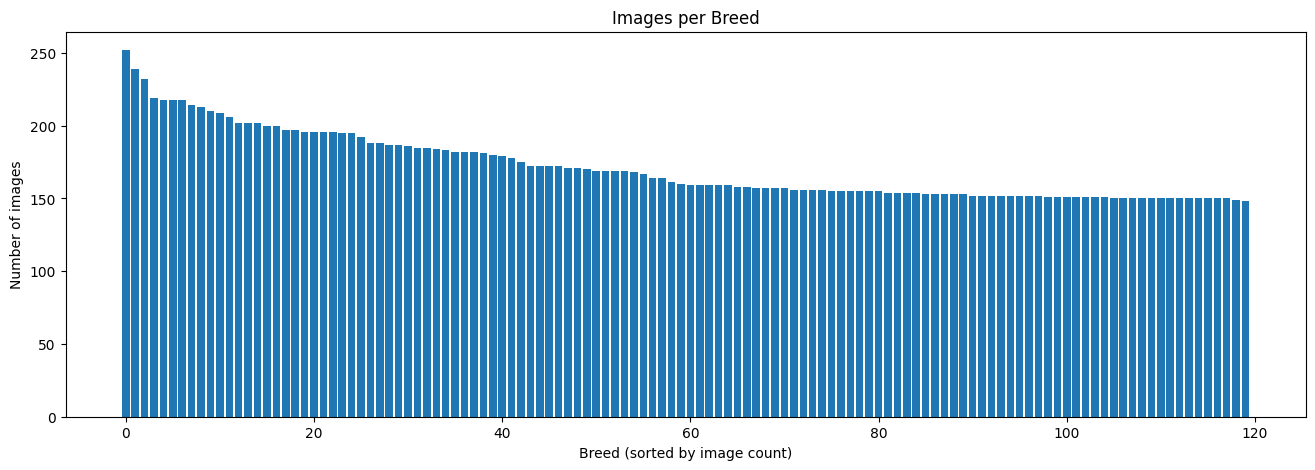

In [2]:
# cell 2: Inventory and class distribution
import os, re, collections
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = os.path.join(EXTRACT_DIR, "Dogs class")

# 1. Anything at this level that is not a folder
stray = [f for f in os.listdir(DATA_DIR) if not os.path.isdir(os.path.join(DATA_DIR, f))]
print("Stray files in Dogs class/:", stray)

# 2. Breed folders (exclude empty folders such as 'Untitled Folder')
breed_rows, skipped = [], []
for d in sorted(os.listdir(DATA_DIR)):
    p = os.path.join(DATA_DIR, d)
    if not os.path.isdir(p):
        continue
    files = [f for f in os.listdir(p) if os.path.isfile(os.path.join(p, f))]
    if len(files) == 0:
        skipped.append(d)
        continue
    breed_rows.append({"folder": d,
                       "breed": re.sub(r"^n\d+-", "", d),
                       "n_images": len(files)})

print("Skipped (empty) folders:", skipped)

df_counts = pd.DataFrame(breed_rows).sort_values("n_images", ascending=False).reset_index(drop=True)
print("\nNumber of breeds:", len(df_counts))
print("Total images    :", df_counts["n_images"].sum())
print("\nImages per breed - summary:")
print(df_counts["n_images"].describe().round(1))
print("\nTop 5 breeds by image count:")
print(df_counts.head(5).to_string(index=False))
print("\nBottom 5 breeds by image count:")
print(df_counts.tail(5).to_string(index=False))

# 3. File extensions across all breed folders
ext_counter = collections.Counter()
for d in df_counts["folder"]:
    for f in os.listdir(os.path.join(DATA_DIR, d)):
        ext_counter[os.path.splitext(f)[1]] += 1
print("\nFile extensions found:", dict(ext_counter))

# 4. Class distribution plot
plt.figure(figsize=(16, 5))
plt.bar(range(len(df_counts)), df_counts["n_images"])
plt.xlabel("Breed (sorted by image count)")
plt.ylabel("Number of images")
plt.title("Images per Breed")
plt.show()

### Class Distribution Findings

- 120 breeds and 20,580 images in total, all in `.jpg` format.
- The empty `Untitled Folder` was excluded; the stray file at the top level is `description.txt`.
- Images per breed: min 148 (redbone), max 252 (Maltese_dog), mean 171.5,
  median 159.5, std 23.2.
- The distribution is mildly imbalanced (largest class is about 1.7x the smallest)
  but falls off smoothly with no extreme outliers, so no resampling is planned.
  A stratified split will keep the same breed proportions in every subset.
- Random guessing across 120 classes would give about 0.83% accuracy, which is
  the floor any useful model must clearly beat.

----- description.txt -----
,
,---------------------------
,


  0%|          | 0/120 [00:00<?, ?it/s]

Total images inspected: 20580
,Corrupt/unreadable    : 0
,
,Color modes:
, mode
,RGB     20579
,RGBA        1
,Name: count, dtype: int64
,
,Width / Height / Aspect ratio / File size (KB):
,          width    height    aspect   file_kb
,count  20580.00  20580.00  20580.00  20580.00
,mean     442.53    385.86      1.19     36.90
,std      142.79    124.86      0.30     32.41
,min       97.00    100.00      0.39      2.94
,25%      361.00    333.00      0.93     22.84
,50%      500.00    375.00      1.33     32.18
,75%      500.00    453.00      1.34     43.92
,max     3264.00   2562.00      3.63   1097.59
,
,Smallest 5 images by width*height:
,                  breed  width  height
,    Rhodesian_ridgeback    105     100
,black-and-tan_coonhound    100     115
,          affenpinscher    109     110
,                clumber    120     102
,          affenpinscher    103     120
,
,Images involved in exact duplicates: 178
,Number of duplicate groups: 89
,Duplicate groups spanning MORE tha

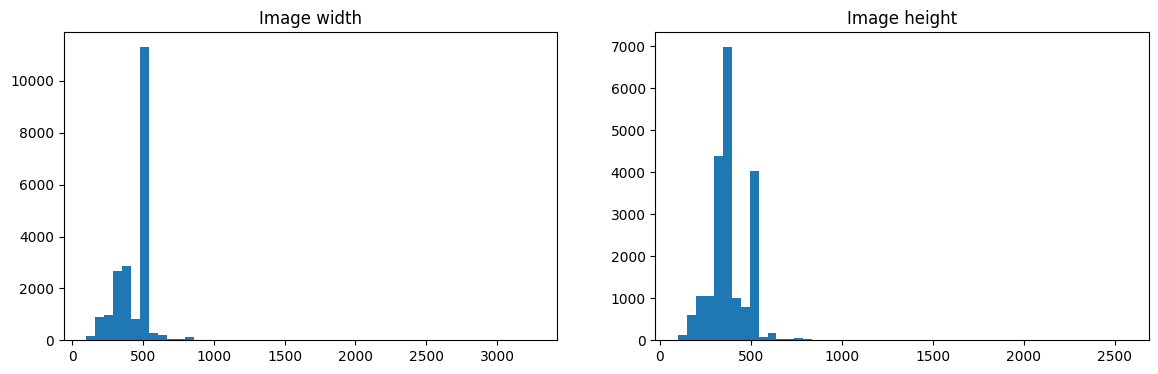

In [3]:
# cell 3: Read description.txt, data quality checks and duplicates
import hashlib
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

# 1. Read the stray description file
with open(os.path.join(DATA_DIR, "description.txt"), "r", errors="ignore") as f:
    print("----- description.txt -----")
    print(f.read()[:2000])
    print("---------------------------\n")

# 2. Inspect every image: corruption, mode, size, file size, hash
records = []
for _, row in tqdm(df_counts.iterrows(), total=len(df_counts)):
    folder_path = os.path.join(DATA_DIR, row["folder"])
    for fname in os.listdir(folder_path):
        p = os.path.join(folder_path, fname)
        rec = {"path": p, "folder": row["folder"], "breed": row["breed"],
               "corrupt": False, "width": None, "height": None, "mode": None,
               "file_kb": os.path.getsize(p) / 1024, "md5": None}
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                rec["width"], rec["height"] = im.size
                rec["mode"] = im.mode
            with open(p, "rb") as fh:
                rec["md5"] = hashlib.md5(fh.read()).hexdigest()
        except Exception as e:
            rec["corrupt"] = True
        records.append(rec)

df_images = pd.DataFrame(records)
df_images.to_csv("/content/image_inventory.csv", index=False)

print("Total images inspected:", len(df_images))
print("Corrupt/unreadable    :", int(df_images["corrupt"].sum()))

ok = df_images[~df_images["corrupt"]].copy()
print("\nColor modes:\n", ok["mode"].value_counts())

ok["aspect"] = ok["width"] / ok["height"]
print("\nWidth / Height / Aspect ratio / File size (KB):")
print(ok[["width", "height", "aspect", "file_kb"]].describe().round(2))

print("\nSmallest 5 images by width*height:")
ok["pixels"] = ok["width"] * ok["height"]
print(ok.nsmallest(5, "pixels")[["breed", "width", "height"]].to_string(index=False))

# 3. Duplicates (exact byte-identical files)
dup_mask = ok.duplicated(subset="md5", keep=False)
dups = ok[dup_mask].sort_values("md5")
print("\nImages involved in exact duplicates:", len(dups))
print("Number of duplicate groups:", dups["md5"].nunique())
cross = dups.groupby("md5")["breed"].nunique()
print("Duplicate groups spanning MORE than one breed:", int((cross > 1).sum()))
if len(dups):
    print(dups[["breed", "md5"]].head(10).to_string(index=False))

# 4. Size distribution plots
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(ok["width"], bins=50);  ax[0].set_title("Image width")
ax[1].hist(ok["height"], bins=50); ax[1].set_title("Image height")
plt.show()

###  Data Quality Findings

- 20,580 images inspected: 0 corrupt/unreadable files; `description.txt` is empty.
- Color modes: 20,579 RGB and 1 RGBA image (will be converted to 3-channel RGB).
- Image sizes vary widely: median 500x375, mean about 442x386, minimum about
  100x100 and maximum 3264x2562. Aspect ratios range from 0.39 to 3.63, with most
  images close to 4:3. A fixed input size is therefore required.
- 89 exact-duplicate pairs (178 images) were found by MD5 hashing. 37 pairs
  appear under two different breeds (conflicting labels) and 52 are copies within
  the same breed.
- Duplicates left in different splits would leak training images into
  validation/test, so they are handled before splitting.

## Section 9: Data Cleaning and Train/Validation/Test Split

**Decisions**
- Cross-breed duplicate pairs: both copies removed (the true label is unknown).
- Same-breed duplicate pairs: one copy kept.
- Stratified 70/15/15 split on file paths, done before any augmentation or resizing.

In [2]:
import os, re, zipfile, urllib.request, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-1-6/dog-breed-120.zip"
ZIP_PATH = "/content/dog-breed-120.zip"
EXTRACT_DIR = "/content/dog_breed_data"
DATA_DIR = os.path.join(EXTRACT_DIR, "Dogs class")
INV_PATH = "/content/image_inventory.csv"

# 1. Dataset on disk?
if not os.path.exists(DATA_DIR):
    if not os.path.exists(ZIP_PATH):
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted.")
else:
    print("Dataset already on disk.")

# 2. Inventory: reload if saved, otherwise rebuild
if os.path.exists(INV_PATH):
    df_images = pd.read_csv(INV_PATH)
    print("Loaded inventory from CSV:", len(df_images), "rows")
else:
    print("Rebuilding inventory...")
    records = []
    for d in tqdm(sorted(os.listdir(DATA_DIR))):
        folder_path = os.path.join(DATA_DIR, d)
        if not os.path.isdir(folder_path) or len(os.listdir(folder_path)) == 0:
            continue                      # skips 'Untitled Folder' and description.txt
        breed = re.sub(r"^n\d+-", "", d)
        for fname in os.listdir(folder_path):
            p = os.path.join(folder_path, fname)
            rec = {"path": p, "folder": d, "breed": breed, "corrupt": False,
                   "width": None, "height": None, "mode": None,
                   "file_kb": os.path.getsize(p) / 1024, "md5": None}
            try:
                with Image.open(p) as im:
                    im.verify()
                with Image.open(p) as im:
                    rec["width"], rec["height"] = im.size
                    rec["mode"] = im.mode
                with open(p, "rb") as fh:
                    rec["md5"] = hashlib.md5(fh.read()).hexdigest()
            except Exception:
                rec["corrupt"] = True
            records.append(rec)
    df_images = pd.DataFrame(records)
    df_images.to_csv(INV_PATH, index=False)

# 3. Sanity check: must match what you saw earlier
print("\nRows           :", len(df_images))
print("Breeds         :", df_images["breed"].nunique())
print("Corrupt        :", int(df_images["corrupt"].sum()))
print("Modes          :", df_images["mode"].value_counts().to_dict())
print("Duplicate md5 rows:", int(df_images.dropna(subset=["md5"]).duplicated("md5", keep=False).sum()))

,Extracted.
,Rebuilding inventory...


  0%|          | 0/122 [00:00<?, ?it/s]


,Rows           : 20580
,Breeds         : 120
,Corrupt        : 0
,Modes          : {'RGB': 20579, 'RGBA': 1}
,Duplicate md5 rows: 178


In [3]:
# cell 4: Inspect the RGBA file, remove duplicates, stratified split
from sklearn.model_selection import train_test_split

# 1. The RGBA image: what is it really?
ok = df_images[~df_images["corrupt"]].copy()
rgba = ok[ok["mode"] == "RGBA"]
print(rgba[["path", "breed", "width", "height"]].to_string(index=False))
with open(rgba.iloc[0]["path"], "rb") as f:
    print("First bytes of file:", f.read(8))

# 2. Duplicates: classify each duplicate group
dup_rows = ok[ok.duplicated("md5", keep=False)]
groups = dup_rows.groupby("md5")["breed"].nunique()
cross_md5 = groups[groups > 1].index
same_md5 = groups[groups == 1].index
print(f"\nCross-breed duplicate groups: {len(cross_md5)}")
print(f"Same-breed duplicate groups : {len(same_md5)}")

print("\nSample cross-breed conflicts:")
cross_pairs = (dup_rows[dup_rows["md5"].isin(cross_md5)]
               .groupby("md5")["breed"].apply(lambda s: " <-> ".join(sorted(s))))
print(cross_pairs.head(15).to_string(index=False))

# 3. Clean
n_before = len(ok)
clean = ok[~ok["md5"].isin(cross_md5)]
n_after_cross = len(clean)
clean = clean.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"\nBefore cleaning        : {n_before}")
print(f"Removed (cross-breed)  : {n_before - n_after_cross}")
print(f"Removed (same-breed)   : {n_after_cross - len(clean)}")
print(f"After cleaning         : {len(clean)}")
print(f"Breeds remaining       : {clean['breed'].nunique()}")
print(f"Duplicate md5 left     : {clean['md5'].duplicated().sum()}")
print(f"Min / max images per breed: {clean['breed'].value_counts().min()} / {clean['breed'].value_counts().max()}")

# 4. Label mapping
class_names = sorted(clean["breed"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
clean["label"] = clean["breed"].map(class_to_idx)

# 5. Stratified 70/15/15 split
SEED = 42
train_df, temp_df = train_test_split(
    clean, test_size=0.30, stratify=clean["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    vc = d["label"].value_counts()
    print(f"{name:5s} images per breed -> min {vc.min()}, max {vc.max()}, breeds present {d['label'].nunique()}")

# 6. Leakage checks
for a, b, an, bn in [(train_df, val_df, "train", "val"),
                     (train_df, test_df, "train", "test"),
                     (val_df, test_df, "val", "test")]:
    p = len(set(a["path"]) & set(b["path"]))
    h = len(set(a["md5"]) & set(b["md5"]))
    print(f"Overlap {an}/{bn}: paths={p}, md5={h}")

# 7. Save splits
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)
print("\nSplits saved.")

                                                                             path             breed  width  height
,/content/dog_breed_data/Dogs class/n02105855-Shetland_sheepdog/n02105855_2933.jpg Shetland_sheepdog    213     189
,First bytes of file: b'\x89PNG\r\n\x1a\n'
,
,Cross-breed duplicate groups: 37
,Same-breed duplicate groups : 52
,
,Sample cross-breed conflicts:
,md5
,    Scotch_terrier <-> West_Highland_white_terrier
,                      Shih-Tzu <-> Tibetan_terrier
,                          Border_collie <-> collie
,             Blenheim_spaniel <-> Japanese_spaniel
,                     Japanese_spaniel <-> papillon
,      Lakeland_terrier <-> wire-haired_fox_terrier
,American_Staffordshire_terrier <-> Staffordshir...
,               Norfolk_terrier <-> Norwich_terrier
,                        groenendael <-> schipperke
,        miniature_schnauzer <-> standard_schnauzer
,                            bloodhound <-> redbone
,         Irish_terrier <-> wire-haired_fox_te

### 9.1 Cleaning and Split Results

- The 1 RGBA file is a PNG saved with a `.jpg` extension; it will be decoded
  as 3-channel RGB in the data pipeline.
- Duplicates: 37 cross-breed pairs (74 images removed, both copies) and 52
  same-breed pairs (52 images removed, one copy kept). The cross-breed conflicts
  occur between visually similar breeds (e.g. Norfolk vs Norwich terrier,
  miniature vs standard schnauzer, Border collie vs collie).
- After cleaning: 20,454 images across 120 breeds (144 to 252 images per breed),
  with no duplicate hashes left.
- Stratified 70/15/15 split (seed 42): train 14,317, validation 3,068, test 3,069.
  Every breed appears in every split (train 101-176, validation 22-38,
  test 21-38 images per breed).
- Leakage check: zero overlap in file paths and in image hashes across all
  three splits.

## Section 10: Exploratory Image Analysis

Looking at the actual images before building a model: how dogs are framed, how
varied the backgrounds are, and how hard it is to tell similar breeds apart.

In [4]:
# cell 5: Sample images and look-alike breeds
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Reload splits if the runtime restarted
if "train_df" not in globals():
    train_df = pd.read_csv("/content/train_split.csv")
    val_df = pd.read_csv("/content/val_split.csv")
    test_df = pd.read_csv("/content/test_split.csv")

# 1. Random sample from the training set
sample = train_df.sample(24, random_state=1)
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(r["breed"][:22], fontsize=9)
    ax.axis("off")
plt.suptitle("Random training images", fontsize=14)
plt.tight_layout()
plt.show()

# 2. Look-alike breeds, one row per breed
def show_breed_rows(breeds, n=5, seed=0):
    fig, axes = plt.subplots(len(breeds), n, figsize=(3 * n, 3 * len(breeds)))
    for i, b in enumerate(breeds):
        imgs = train_df[train_df["breed"] == b].sample(n, random_state=seed)
        for j, (_, r) in enumerate(imgs.iterrows()):
            with Image.open(r["path"]) as im:
                axes[i, j].imshow(im.convert("RGB"))
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_title(b, fontsize=11, loc="left")
    plt.tight_layout()
    plt.show()

show_breed_rows(["Norfolk_terrier", "Norwich_terrier"])
show_breed_rows(["miniature_schnauzer", "standard_schnauzer"])
show_breed_rows(["Border_collie", "collie"])

Output hidden; open in https://colab.research.google.com to view.

### 10.1 Visual Observations

- Dog framing varies widely: close-up faces, full-body shots, and small dogs
  inside large scenes. Both portrait and landscape images are present.
- Many images are cluttered: people, two dogs in one frame, and objects in front
  of the dog (e.g. a wire cage).
- Image quirks seen in a random sample: a website watermark, a black border,
  an unusual colour cast, and a dog wearing a costume.
- Some labels may be ambiguous or noisy, which limits the accuracy that can
  realistically be expected.
- Implication: moderate augmentation (horizontal flip, small zoom/rotation,
  mild brightness change) is appropriate, and pretrained models should cope
  with background variation better than a CNN trained from scratch.

## Section 11: Data Pipeline

**Design decisions**
- Images are read from disk in batches with `tf.data`. Loading all 20,454 images
  into one array would need about 12 GB of RAM as floats, which crashes Colab.
- All images are resized directly to 224x224 (the input size of MobileNetV2 and
  EfficientNetB0). Most images are about 4:3, so the distortion is mild, and
  direct resizing avoids cropping the dog out of the frame.
- `decode_image(channels=3)` is used so the PNG-in-.jpg file loads correctly.
- Images are stored as uint8 (0-255) and cached on disk after the first pass, so
  later epochs are fast. Each model does its own normalisation as its first layer,
  because MobileNetV2 and EfficientNetB0 expect different input ranges.
- Only the training set is shuffled. The validation and test order stays fixed so
  predictions can be matched to file paths later.
- Augmentation is applied inside the model (training only), so validation and
  test images are never augmented.

In [2]:
import os, re, zipfile, urllib.request, hashlib
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-1-6/dog-breed-120.zip"
ZIP_PATH = "/content/dog-breed-120.zip"
EXTRACT_DIR = "/content/dog_breed_data"
DATA_DIR = os.path.join(EXTRACT_DIR, "Dogs class")
SEED = 42

# 1. Download and extract if missing
if not os.path.exists(DATA_DIR):
    if not os.path.exists(ZIP_PATH):
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted.")
else:
    print("Dataset already on disk.")

# 2. Inventory (sorted so the order is reproducible); skips empty folders and description.txt
records = []
for d in tqdm(sorted(os.listdir(DATA_DIR))):
    folder_path = os.path.join(DATA_DIR, d)
    if not os.path.isdir(folder_path) or len(os.listdir(folder_path)) == 0:
        continue
    breed = re.sub(r"^n\d+-", "", d)
    for fname in sorted(os.listdir(folder_path)):
        p = os.path.join(folder_path, fname)
        try:
            with Image.open(p) as im:
                im.verify()
            with open(p, "rb") as fh:
                md5 = hashlib.md5(fh.read()).hexdigest()
            records.append({"path": p, "breed": breed, "md5": md5})
        except Exception:
            print("Corrupt/unreadable, skipped:", p)

ok = pd.DataFrame(records)
print("\nInventory:", len(ok), "images,", ok["breed"].nunique(), "breeds")

# 3. Duplicates: remove cross-breed pairs entirely, keep one copy of same-breed pairs
dup_rows = ok[ok.duplicated("md5", keep=False)]
groups = dup_rows.groupby("md5")["breed"].nunique()
cross_md5 = groups[groups > 1].index
same_md5 = groups[groups == 1].index
print(f"Cross-breed duplicate groups: {len(cross_md5)} | Same-breed duplicate groups: {len(same_md5)}")

clean = ok[~ok["md5"].isin(cross_md5)]
clean = clean.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"After cleaning: {len(clean)} images, {clean['breed'].nunique()} breeds, "
      f"duplicate md5 left: {clean['md5'].duplicated().sum()}")

# 4. Labels and stratified 70/15/15 split
class_names = sorted(clean["breed"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
clean["label"] = clean["breed"].map(class_to_idx)

train_df, temp_df = train_test_split(
    clean, test_size=0.30, stratify=clean["label"], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    vc = d["label"].value_counts()
    print(f"{name:5s} per breed -> min {vc.min()}, max {vc.max()}, breeds present {d['label'].nunique()}")

# 5. Leakage checks
for a, b, an, bn in [(train_df, val_df, "train", "val"),
                     (train_df, test_df, "train", "test"),
                     (val_df, test_df, "val", "test")]:
    print(f"Overlap {an}/{bn}: paths={len(set(a['path']) & set(b['path']))}, "
          f"md5={len(set(a['md5']) & set(b['md5']))}")

# 6. Save splits
train_df.to_csv("/content/train_split.csv", index=False)
val_df.to_csv("/content/val_split.csv", index=False)
test_df.to_csv("/content/test_split.csv", index=False)
print("\nSplits saved.")

,Extracted.


  0%|          | 0/122 [00:00<?, ?it/s]


,Inventory: 20580 images, 120 breeds
,Cross-breed duplicate groups: 37 | Same-breed duplicate groups: 52
,After cleaning: 20454 images, 120 breeds, duplicate md5 left: 0
,
,Train: 14317 | Val: 3068 | Test: 3069
,train per breed -> min 101, max 176, breeds present 120
,val   per breed -> min 22, max 38, breeds present 120
,test  per breed -> min 21, max 38, breeds present 120
,Overlap train/val: paths=0, md5=0
,Overlap train/test: paths=0, md5=0
,Overlap val/test: paths=0, md5=0
,
,Splits saved.


In [3]:
# cell 6: Build the tf.data pipeline
import os, glob, time
import numpy as np
import pandas as pd
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Reload splits if the runtime restarted
if "train_df" not in globals():
    train_df = pd.read_csv("/content/train_split.csv")
    val_df = pd.read_csv("/content/val_split.csv")
    test_df = pd.read_csv("/content/test_split.csv")

# Label mapping (must match the 'label' column saved in the CSVs)
class_names = sorted(train_df["breed"].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
assert all(train_df["breed"].map(class_to_idx) == train_df["label"]), "Label mismatch!"
NUM_CLASSES = len(class_names)
print("Classes:", NUM_CLASSES)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Remove stale cache files from earlier runs
for f in glob.glob("/content/cache_*"):
    os.remove(f)

def load_image(path, label):
    raw = tf.io.read_file(path)
    img = tf.io.decode_image(raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)          # float32, still 0-255
    img = tf.cast(tf.round(img), tf.uint8)        # store compactly
    return img, label

def make_cached(df, name):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label"].values.astype("int32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.cache(f"/content/cache_{name}")

train_cached = make_cached(train_df, "train")
val_cached   = make_cached(val_df, "val")
test_cached  = make_cached(test_df, "test")

# Warm up caches: one full pass over each split
def warm_up(ds, df, name):
    t = time.time()
    n, first = 0, None
    for x, y in ds.batch(256):
        if first is None:
            first = (x.shape, x.dtype.name, int(tf.reduce_min(x)),
                     int(tf.reduce_max(x)), int(tf.reduce_min(y)), int(tf.reduce_max(y)))
        n += int(x.shape[0])
    print(f"{name:5s}: {n} images (expected {len(df)}) in {time.time()-t:.0f}s | "
          f"first batch (shape, dtype, px min, px max, label min, label max) = {first}")
    assert n == len(df)

warm_up(train_cached, train_df, "train")
warm_up(val_cached, val_df, "val")
warm_up(test_cached, test_df, "test")

# Final datasets
train_ds = (train_cached.shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds  = val_cached.batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = test_cached.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("\ntrain_ds spec:", train_ds.element_spec)
print("Steps per epoch (train/val/test):",
      len(train_df)//BATCH_SIZE + (len(train_df) % BATCH_SIZE > 0),
      len(val_df)//BATCH_SIZE + (len(val_df) % BATCH_SIZE > 0),
      len(test_df)//BATCH_SIZE + (len(test_df) % BATCH_SIZE > 0))

TensorFlow: 2.21.0
,GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
,Classes: 120
,train: 14317 images (expected 14317) in 27s | first batch (shape, dtype, px min, px max, label min, label max) = (TensorShape([256, 224, 224, 3]), 'uint8', 0, 255, 0, 118)
,val  : 3068 images (expected 3068) in 5s | first batch (shape, dtype, px min, px max, label min, label max) = (TensorShape([256, 224, 224, 3]), 'uint8', 0, 255, 0, 119)
,test : 3069 images (expected 3069) in 7s | first batch (shape, dtype, px min, px max, label min, label max) = (TensorShape([256, 224, 224, 3]), 'uint8', 0, 255, 0, 119)
,
,train_ds spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
,Steps per epoch (train/val/test): 448 96 96


## Section 12: Data Augmentation

Augmentation is built as Keras layers (applied inside the model, training only) so the validation and test images are never altered. Settings are checked visually on a sample image below.

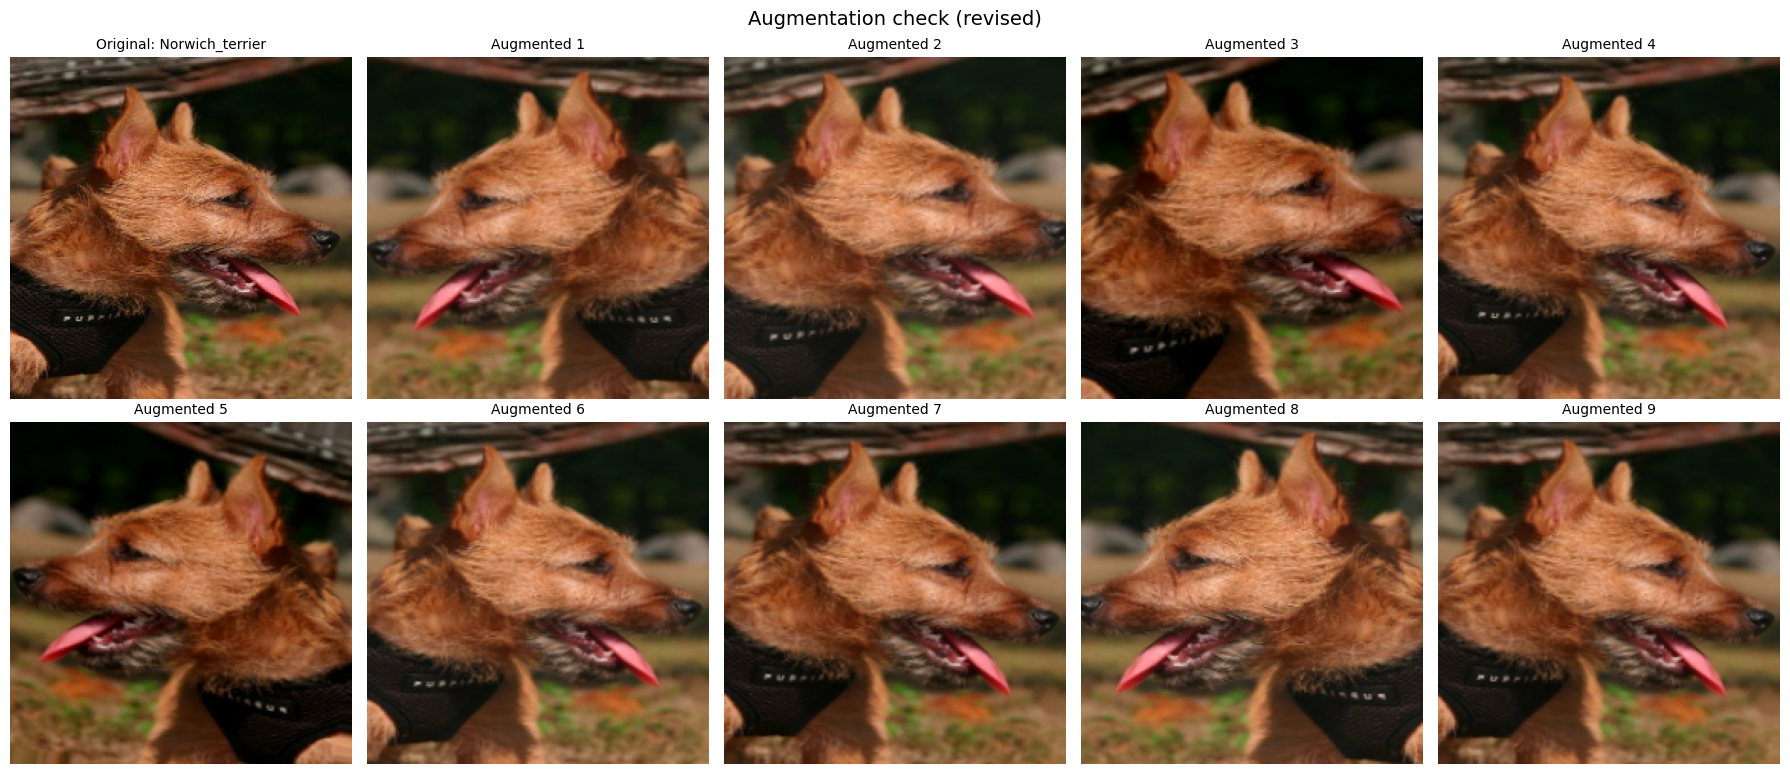

In [5]:
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03, fill_mode="nearest"),               # about ±11 degrees
    layers.RandomZoom(height_factor=(-0.15, 0.0), fill_mode="nearest"),  # zoom in only
    layers.RandomBrightness(0.05, value_range=(0, 255)),
], name="data_augmentation")

for images, labels in train_ds.take(1):
    img = images[0]
    label_name = class_names[int(labels[0])]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes[0, 0].imshow(img.numpy())
axes[0, 0].set_title(f"Original: {label_name}", fontsize=10)
axes[0, 0].axis("off")

for i, ax in enumerate(axes.ravel()[1:]):
    aug = data_augmentation(tf.expand_dims(img, 0), training=True)[0]
    aug = tf.cast(tf.clip_by_value(aug, 0, 255), tf.uint8)
    ax.imshow(aug.numpy())
    ax.set_title(f"Augmented {i+1}", fontsize=10)
    ax.axis("off")

plt.suptitle("Augmentation check (revised)", fontsize=14)
plt.tight_layout()
plt.show()

### 12.1 Augmentation Check

- Augmentation settings: horizontal flip, rotation about ±11°, zoom-in up to 15%,
  brightness ±5% of the pixel range.
- A first check with zoom ±10% and brightness ±10% showed visibly darkened images
  (a problem for dark-coated breeds such as the pug, whose face lost detail) and
  small mirrored fragments in the image corners from the default reflect fill.
- Settings were revised to zoom-in only, nearest-pixel edge fill and half the
  brightness range.
- In the revised check, augmented images keep realistic colours and the dog remains
  clearly recognisable, with no corner artifacts.

## Section 13: Baseline CNN

A small CNN trained from scratch sets the performance floor that the
transfer-learning models must beat.

**Architecture:** 4 convolution blocks (32, 64, 128, 256 filters), each with
Conv2D + BatchNormalization + ReLU + MaxPooling, followed by
GlobalAveragePooling, Dropout(0.4) and a 120-way softmax layer. Global average
pooling is used instead of Flatten to keep the parameter count small.

**Experiments**
- Experiment A: baseline without augmentation
- Experiment B: baseline with augmentation

**Training setup:** Adam (lr 1e-3), sparse categorical cross-entropy, batch size 32,
up to 30 epochs with EarlyStopping (val_loss, patience 6, best weights restored)
and ReduceLROnPlateau.

**Metrics:** accuracy and top-5 accuracy. Random guessing would give 0.83%
top-1 and 4.17% top-5, so those are the floors.

In [6]:
# cell 8: Model builder and training helpers
import os, time
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
os.makedirs("/content/models", exist_ok=True)

results = {}   # stores real results of every model for the comparison section

def build_baseline_cnn(use_augmentation=False, name="baseline_cnn"):
    inputs = keras.Input(shape=(224, 224, 3), name="image")
    x = inputs
    if use_augmentation:
        x = data_augmentation(x)            # from code cell 7 (works on 0-255 values)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name)

def compile_model(model, lr=1e-3):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy",
                 keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")])

def train_model(model, name, epochs=30, patience=6):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                          patience=3, min_lr=1e-6),
    ]
    t0 = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                        callbacks=callbacks, verbose=2)
    train_time = time.time() - t0
    m = model.evaluate(val_ds, verbose=0, return_dict=True)   # best weights restored
    results[name] = {
        "val_loss": m["loss"], "val_acc": m["accuracy"], "val_top5": m["top5_acc"],
        "epochs_run": len(history.history["loss"]),
        "train_time_min": train_time / 60,
        "params": model.count_params(),
    }
    model.save(f"/content/models/{name}.keras")
    print(f"\n{name}: val_loss={m['loss']:.4f}  val_acc={m['accuracy']:.4f}  "
          f"val_top5={m['top5_acc']:.4f}  epochs={len(history.history['loss'])}  "
          f"time={train_time/60:.1f} min")
    return history

def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{title} - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val")
    ax[1].set_title(f"{title} - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

# Build Experiment A model (no augmentation) and inspect it
model_A = build_baseline_cnn(use_augmentation=False, name="baseline_cnn_noaug")
compile_model(model_A)
model_A.summary()

Model: "baseline_cnn_noaug"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        30,840 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,696 (1.60 MB)

 Trainable params: 419,736 (1.60 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
,448/448 - 56s - 125ms/step - accuracy: 0.0154 - loss: 4.8752 - top5_acc: 0.0722 - val_accuracy: 0.0192 - val_loss: 4.7575 - val_top5_acc: 0.0782 - learning_rate: 0.0010
,Epoch 2/30
,448/448 - 31s - 70ms/step - accuracy: 0.0237 - loss: 4.6840 - top5_acc: 0.0996 - val_accuracy: 0.0215 - val_loss: 4.7031 - val_top5_acc: 0.0867 - learning_rate: 0.0010
,Epoch 3/30
,448/448 - 32s - 71ms/step - accuracy: 0.0321 - loss: 4.5666 - top5_acc: 0.1275 - val_accuracy: 0.0297 - val_loss: 4.6216 - val_top5_acc: 0.1186 - learning_rate: 0.0010
,Epoch 4/30
,448/448 - 32s - 71ms/step - accuracy: 0.0426 - loss: 4.4477 - top5_acc: 0.1637 - val_accuracy: 0.0528 - val_loss: 4.3918 - val_top5_acc: 0.1868 - learning_rate: 0.0010
,Epoch 5/30
,448/448 - 32s - 71ms/step - accuracy: 0.0565 - loss: 4.3151 - top5_acc: 0.2023 - val_accuracy: 0.0362 - val_loss: 4.5235 - val_top5_acc: 0.1470 - learning_rate: 0.0010
,Epoch 6/30
,448/448 - 32s - 71ms/step - accuracy: 0.0717 - loss: 4.1780 - top5_acc: 0.2403 - v

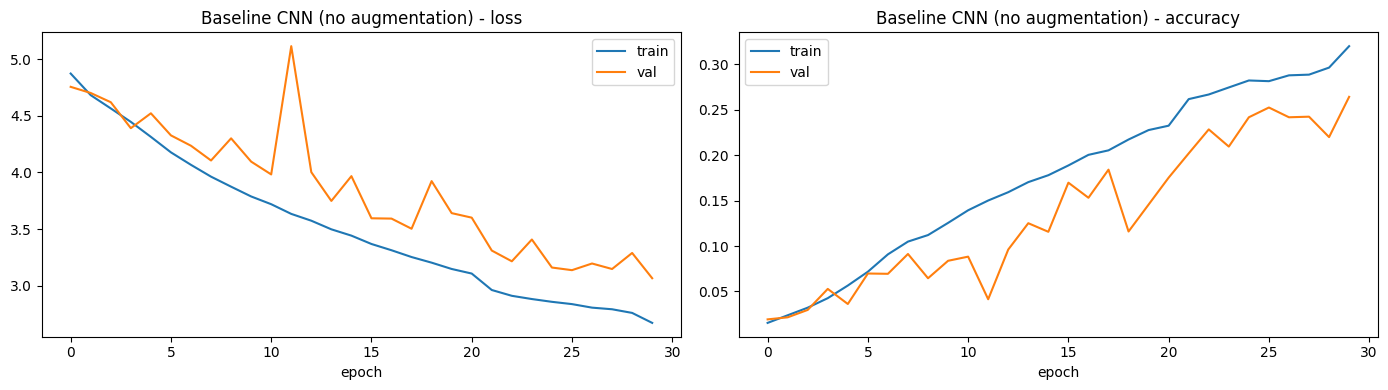

In [7]:
# cell 9: Train Experiment A (no augmentation)
history_A = train_model(model_A, "baseline_cnn_noaug")
plot_history(history_A, "Baseline CNN (no augmentation)")

### 13.1 Experiment A Results (no augmentation)

- Model: 420,696 parameters (419,736 trainable).
- Trained for all 30 epochs (16.8 minutes); early stopping did not trigger, and
  the learning rate was reduced at epoch 22 (to 5e-4) and epoch 30 (to 2.5e-4).
- Validation results (best weights = final epoch): accuracy 0.2643, top-5 accuracy
  0.5632, loss 3.0647. Random guessing would give 0.83% and 4.17%.
- Final training accuracy was 0.3202, so the train/validation gap is small. The
  model is underfitting: both curves were still improving when the epoch limit was
  reached, so this is a floor and not the best a baseline could achieve.
- Validation loss was noisy (a spike at epoch 12), typical of BatchNorm with a
  high initial learning rate, and it stabilised after the learning rate reductions.

Total params: 420696
,Epoch 1/30
,448/448 - 63s - 141ms/step - accuracy: 0.0192 - loss: 4.8102 - top5_acc: 0.0764 - val_accuracy: 0.0196 - val_loss: 4.7102 - val_top5_acc: 0.0860 - learning_rate: 0.0010
,Epoch 2/30
,448/448 - 57s - 128ms/step - accuracy: 0.0297 - loss: 4.6182 - top5_acc: 0.1129 - val_accuracy: 0.0326 - val_loss: 4.6095 - val_top5_acc: 0.1164 - learning_rate: 0.0010
,Epoch 3/30
,448/448 - 57s - 128ms/step - accuracy: 0.0339 - loss: 4.5104 - top5_acc: 0.1389 - val_accuracy: 0.0359 - val_loss: 4.5544 - val_top5_acc: 0.1336 - learning_rate: 0.0010
,Epoch 4/30
,448/448 - 57s - 128ms/step - accuracy: 0.0487 - loss: 4.3924 - top5_acc: 0.1740 - val_accuracy: 0.0427 - val_loss: 4.5311 - val_top5_acc: 0.1421 - learning_rate: 0.0010
,Epoch 5/30
,448/448 - 58s - 128ms/step - accuracy: 0.0553 - loss: 4.2796 - top5_acc: 0.2072 - val_accuracy: 0.0463 - val_loss: 4.4360 - val_top5_acc: 0.1776 - learning_rate: 0.0010
,Epoch 6/30
,448/448 - 57s - 128ms/step - accuracy: 0.0710 - loss: 4.

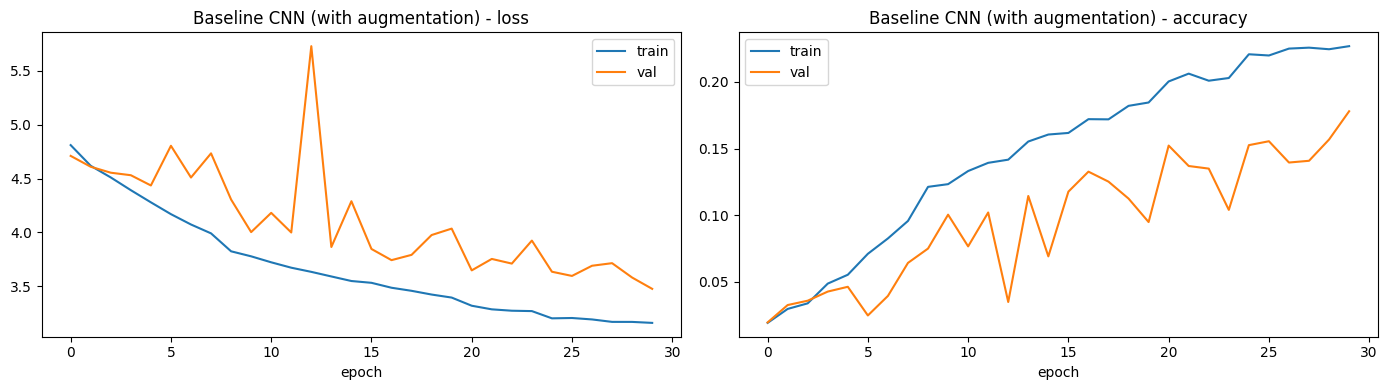


,                     val_acc  val_top5  val_loss  epochs_run  train_time_min  \
,baseline_cnn_noaug   0.2643    0.5632    3.0647        30.0         16.7623   
,baseline_cnn_aug     0.1780    0.4580    3.4773        30.0         29.2132   
,
,                      params  
,baseline_cnn_noaug  420696.0  
,baseline_cnn_aug    420696.0  


In [8]:
# Experiment B: the same baseline with augmentation
import json

keras.utils.set_random_seed(42)
model_B = build_baseline_cnn(use_augmentation=True, name="baseline_cnn_aug")
compile_model(model_B)
print("Total params:", model_B.count_params())

history_B = train_model(model_B, "baseline_cnn_aug")
plot_history(history_B, "Baseline CNN (with augmentation)")

# Side-by-side comparison of the real results so far
comp = pd.DataFrame(results).T[["val_acc", "val_top5", "val_loss", "epochs_run", "train_time_min", "params"]]
print("\n", comp.round(4))

with open("/content/results.json", "w") as f:
    json.dump(results, f, indent=2)

## Section 14: Baseline Results and Comparison (Experiment A vs B)

| Model | Val Acc | Val Top-5 | Val Loss | Train time |
|---|---|---|---|---|
| Baseline CNN, no augmentation | 26.43% | 56.32% | 3.0647 | 16.8 min |
| Baseline CNN, with augmentation | 17.80% | 45.80% | 3.4773 | 29.2 min |

### 14.1 Findings

- Both baselines underfit: final training accuracy (32.0% and 22.7%) is only slightly above validation accuracy, and the curves were still improving at epoch 30.
- Augmentation lowered validation accuracy from 26.43% to 17.80% and almost doubled the training time. With only 420,696 parameters the model has no spare capacity, so the harder augmented task slowed learning instead of regularising it.
- Both models are far above random guessing (0.83% top-1, 4.17% top-5) but too weak for 120 fine-grained breeds. Learning fur texture, ear shape and face structure from scratch on about 14,000 images is hard.
- Decision: move to transfer learning with an ImageNet-pretrained backbone.

## Section 15: Transfer Learning Setup (EfficientNetB0)

**Design decisions**
- Backbone: EfficientNetB0 pretrained on ImageNet (4,049,571 parameters, `include_top=False`), followed by GlobalAveragePooling, Dropout(0.3) and a 120-way softmax layer (153,720 parameters). Total: 4,203,291 parameters.
- EfficientNet rescales its input internally, so images are passed as raw 0-255 pixels (no division by 255).
- Augmentation inside the model, training only: horizontal flip, rotation about ±11° and zoom ±10%. This is simpler than the settings in Section 12 (zoom-in only, nearest fill); see the limitations in Section 23.
- The splits are reloaded from the saved CSV files and the pipeline is rebuilt with batch size 32. Class names are read from the `label` and `breed` columns and checked (labels 0-119, exactly one breed per label), so predictions always map to the correct breed.
- Two-stage training: first train only the new head with the backbone frozen, then fine-tune the top backbone layers at a low learning rate.

In [11]:
import os, json, time, numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

SEED, IMG, BATCH = 42, 224, 32
tf.keras.utils.set_random_seed(SEED)

train_df = pd.read_csv('/content/train_split.csv')
val_df   = pd.read_csv('/content/val_split.csv')
test_df  = pd.read_csv('/content/test_split.csv')

PATH_COL = 'path'
print('Columns:', list(train_df.columns))

# class names come straight from the CSVs, so index i always matches label i
all_df = pd.concat([train_df, val_df, test_df])
label_to_breed = (all_df.drop_duplicates('label')
                  .assign(name=lambda d: d['path'].map(lambda p: Path(p).parent.name.split('-', 1)[1]))
                  .set_index('label')['name'].sort_index())
class_names = label_to_breed.tolist()
NUM_CLASSES = len(class_names)
print('Classes:', NUM_CLASSES)

assert list(label_to_breed.index) == list(range(NUM_CLASSES)), 'labels are not 0..N-1'
assert (all_df.groupby('label')['breed'].nunique() == 1).all(), 'a label maps to more than one breed'
print('Label check OK. Example:', class_names[:3])

def load_img(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)   # handles the RGBA-as-jpg file
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.float32), label                              # keep 0-255 for EfficientNet

def make_ds(df, training):
    ds = tf.data.Dataset.from_tensor_slices((df[PATH_COL].values, df['label'].values.astype('int32')))
    ds = ds.map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.shuffle(2000, seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)
print(len(train_df), len(val_df), len(test_df))

Columns: ['path', 'breed', 'md5', 'label']
,Classes: 120
,Label check OK. Example: ['Afghan_hound', 'African_hunting_dog', 'Airedale']
,14317 3068 3069


In [12]:
def build_model(trainable_backbone=False):
    base = keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                             input_shape=(IMG, IMG, 3))
    base.trainable = trainable_backbone

    inputs = keras.Input(shape=(IMG, IMG, 3))
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.03)(x)
    x = layers.RandomZoom(0.1)(x)
    x = base(x, training=False)              # keep BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inputs, outputs, name='effnetb0_dogs'), base

model, base = build_model()
metrics = ['accuracy', keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_acc')]
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=metrics)
model.summary()

,16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "effnetb0_dogs"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_2 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_2 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 120)            │       153,720 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,203,291 (16.03 MB)

 Trainable params: 153,720 (600.47 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Section 16: Stage 1: Feature Extraction (Frozen Backbone)

**Design decisions**
- The new Dense layer starts with random weights. Training everything at once would let its large random gradients damage the pretrained features, so the backbone is frozen and only the head is trained.
- Adam with learning rate 1e-3, up to 12 epochs, EarlyStopping (val_loss, patience 4, best weights restored) and ReduceLROnPlateau.

In [13]:
cb1 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
]
t0 = time.time()
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=12, callbacks=cb1, verbose=2)
t1 = (time.time() - t0) / 60
r1 = model.evaluate(val_ds, verbose=0, return_dict=True)
print(f"\nStage 1 -> val_acc={r1['accuracy']:.4f} val_top5={r1['top5_acc']:.4f} val_loss={r1['loss']:.4f} time={t1:.1f} min")

Epoch 1/12
,448/448 - 57s - 127ms/step - accuracy: 0.6499 - loss: 1.6183 - top5_acc: 0.8883 - val_accuracy: 0.8341 - val_loss: 0.6367 - val_top5_acc: 0.9801 - learning_rate: 0.0010
,Epoch 2/12
,448/448 - 46s - 102ms/step - accuracy: 0.8176 - loss: 0.6645 - top5_acc: 0.9767 - val_accuracy: 0.8497 - val_loss: 0.5126 - val_top5_acc: 0.9847 - learning_rate: 0.0010
,Epoch 3/12
,448/448 - 46s - 102ms/step - accuracy: 0.8498 - loss: 0.5231 - top5_acc: 0.9860 - val_accuracy: 0.8582 - val_loss: 0.4767 - val_top5_acc: 0.9827 - learning_rate: 0.0010
,Epoch 4/12
,448/448 - 45s - 100ms/step - accuracy: 0.8631 - loss: 0.4540 - top5_acc: 0.9892 - val_accuracy: 0.8546 - val_loss: 0.4647 - val_top5_acc: 0.9831 - learning_rate: 0.0010
,Epoch 5/12
,448/448 - 45s - 100ms/step - accuracy: 0.8789 - loss: 0.4043 - top5_acc: 0.9919 - val_accuracy: 0.8563 - val_loss: 0.4568 - val_top5_acc: 0.9840 - learning_rate: 0.0010
,Epoch 6/12
,448/448 - 48s - 107ms/step - accuracy: 0.8931 - loss: 0.3584 - top5_acc: 0.994

### 16.1 Stage 1 Results (frozen backbone)

- Only the head is trained: 153,720 trainable parameters out of 4,203,291.
- After the first epoch the model already reached 83.41% validation accuracy, compared with 26.43% for the best baseline after 30 epochs. This confirms that the pretrained features suit the task.
- Best validation loss (0.4394) came at epoch 11 and those weights were restored. Validation accuracy 85.82%, top-5 accuracy 98.31%. Training time 10.0 minutes.
- The learning rate was reduced from 1e-3 to 5e-4 at epoch 8.
- Training accuracy kept rising (to 93.0%) while validation accuracy stayed around 85-86% from epoch 3 onward, so the head alone has already extracted most of what it can.

## Section 17: Stage 2: Fine-Tuning the Top of the Backbone

**Design decisions**
- Only the top layers of the backbone are unfrozen (23 of 238 layers are trainable). All BatchNormalization layers stay frozen.
- Learning rate 1e-4 (10x smaller than Stage 1); the model is re-compiled after changing `trainable`.
- EarlyStopping (val_loss, patience 5, best weights restored), ReduceLROnPlateau and a ModelCheckpoint on the best validation loss.

In [14]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
print('Trainable backbone layers:', sum(l.trainable for l in base.layers), 'of', len(base.layers))

model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss='sparse_categorical_crossentropy', metrics=metrics)

cb2 = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint('/content/best_effnetb0.keras', monitor='val_loss', save_best_only=True),
]
t0 = time.time()
hist2 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=cb2, verbose=2)
t2 = (time.time() - t0) / 60
r2 = model.evaluate(val_ds, verbose=0, return_dict=True)
print(f"\nStage 2 -> val_acc={r2['accuracy']:.4f} val_top5={r2['top5_acc']:.4f} val_loss={r2['loss']:.4f} time={t2:.1f} min")

Trainable backbone layers: 23 of 238
,Epoch 1/20
,448/448 - 76s - 169ms/step - accuracy: 0.9262 - loss: 0.2292 - top5_acc: 0.9955 - val_accuracy: 0.8488 - val_loss: 0.4954 - val_top5_acc: 0.9814 - learning_rate: 1.0000e-04
,Epoch 2/20
,448/448 - 53s - 118ms/step - accuracy: 0.9331 - loss: 0.2029 - top5_acc: 0.9989 - val_accuracy: 0.8523 - val_loss: 0.4906 - val_top5_acc: 0.9834 - learning_rate: 1.0000e-04
,Epoch 3/20
,448/448 - 48s - 107ms/step - accuracy: 0.9438 - loss: 0.1727 - top5_acc: 0.9992 - val_accuracy: 0.8514 - val_loss: 0.5164 - val_top5_acc: 0.9811 - learning_rate: 1.0000e-04
,Epoch 4/20
,
,Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
,448/448 - 51s - 114ms/step - accuracy: 0.9474 - loss: 0.1590 - top5_acc: 0.9993 - val_accuracy: 0.8491 - val_loss: 0.5113 - val_top5_acc: 0.9814 - learning_rate: 1.0000e-04
,Epoch 5/20
,448/448 - 48s - 107ms/step - accuracy: 0.9601 - loss: 0.1313 - top5_acc: 0.9994 - val_accuracy: 0.8520 - val_loss: 0.5055 - val

### 17.1 Stage 2 Results (fine-tuning)

- Early stopping ended training after 7 epochs; the best epoch was epoch 2 (validation loss 0.4906) and those weights were restored. Validation accuracy 85.23%, top-5 accuracy 98.34%. Training time 6.2 minutes.
- Fine-tuning did **not** improve on Stage 1: validation accuracy changed from 85.82% to 85.23% and validation loss rose from 0.4394 to 0.4906. The 0.6 point accuracy difference is about 18 images out of 3,068, which is within normal noise.
- Training accuracy climbed from 92.6% to 96.7% while validation accuracy stayed near 85%. The gap of about 12 points shows that unfreezing layers made the model start to memorise the training set.
- Interpretation: the ImageNet features are already well suited to dog breeds, so most of the achievable accuracy comes from the frozen backbone and the new head. The fine-tuned checkpoint is the model evaluated on the test set below.

## Section 18: Training Curves

The dashed line marks where fine-tuning (Stage 2) begins.

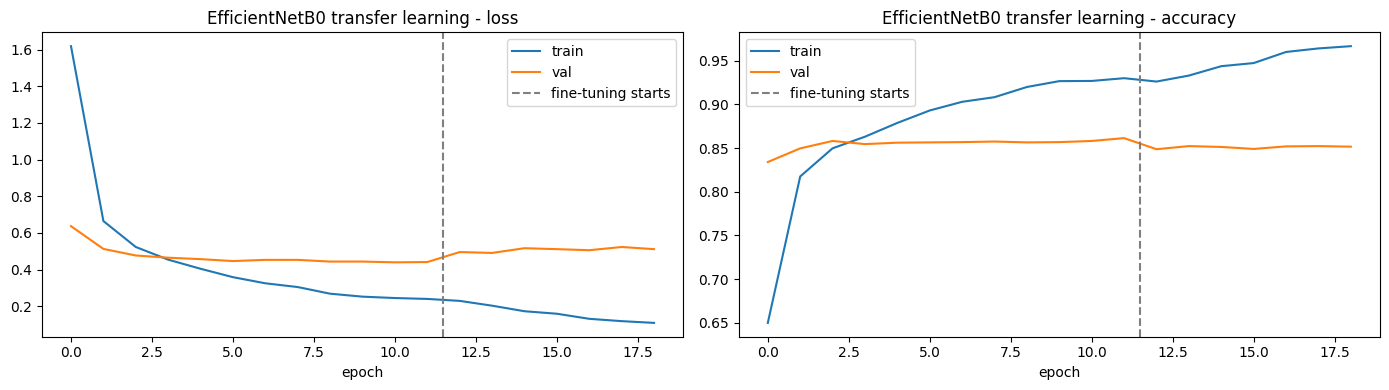

In [15]:
import matplotlib.pyplot as plt
def merged(key):
    return hist1.history[key] + hist2.history[key]
n1 = len(hist1.history['loss'])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (k, title) in zip(ax, [('loss', 'loss'), ('accuracy', 'accuracy')]):
    a.plot(merged(k), label='train'); a.plot(merged('val_' + k), label='val')
    a.axvline(n1 - 0.5, ls='--', c='gray', label='fine-tuning starts')
    a.set_title(f'EfficientNetB0 transfer learning - {title}'); a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); plt.show()

### 18.1 Curve Observations

- Stage 1: validation accuracy jumps in the first epoch and then flattens at about 85-86%, while training accuracy keeps rising.
- Stage 2: training loss falls further, but validation loss does not improve (0.495 at the start, about 0.51 at the end), so the train/validation gap widens. This is mild overfitting, which is why early stopping restored the epoch-2 weights.
- Validation curves are smooth, unlike the noisy baseline curves, because pretrained features are stable.

## Section 19: Final Evaluation on the Test Set

The test set (3,069 images) was not used for training, early stopping or model selection, so it gives an unbiased estimate of performance.

In [16]:
from sklearn.metrics import classification_report, confusion_matrix

test_res = model.evaluate(test_ds, verbose=0, return_dict=True)
print(f"TEST  accuracy={test_res['accuracy']:.4f}  top-5={test_res['top5_acc']:.4f}  loss={test_res['loss']:.4f}")

probs  = model.predict(test_ds, verbose=0)
y_true = test_df['label'].values
y_pred = probs.argmax(1)
short = list(class_names)
rep = classification_report(y_true, y_pred, target_names=short, output_dict=True, zero_division=0)
rep_df = pd.DataFrame(rep).T.iloc[:NUM_CLASSES].sort_values('f1-score')
print('\nMacro F1:', round(rep['macro avg']['f1-score'], 4))
rep_df.head(10)

TEST  accuracy=0.8508  top-5=0.9834  loss=0.5146
,
,Macro F1: 0.8454


,precision,recall,f1-score,support
collie,0.555556,0.227273,0.322581,22.0
Eskimo_dog,0.428571,0.409091,0.418605,22.0
miniature_poodle,0.562500,0.409091,0.473684,22.0
Siberian_husky,0.619048,0.448276,0.520000,29.0
Rhodesian_ridgeback,0.652174,0.576923,0.612245,26.0
toy_poodle,0.533333,0.727273,0.615385,22.0
kelpie,0.722222,0.565217,0.634146,23.0
Appenzeller,0.636364,0.636364,0.636364,22.0
Labrador_retriever,0.750000,0.576923,0.652174,26.0
English_foxhound,0.695652,0.695652,0.695652,23.0


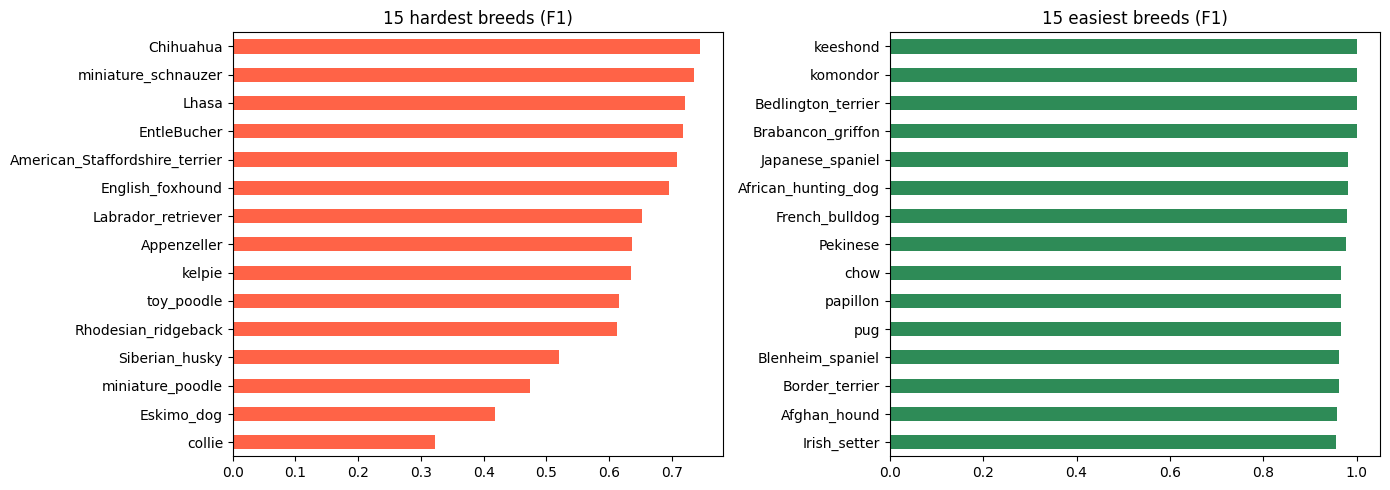

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
rep_df.head(15)['f1-score'].plot.barh(ax=ax[0], color='tomato'); ax[0].set_title('15 hardest breeds (F1)')
rep_df.tail(15)['f1-score'].plot.barh(ax=ax[1], color='seagreen'); ax[1].set_title('15 easiest breeds (F1)')
plt.tight_layout(); plt.show()

### 19.1 Test Results

- Test accuracy 85.08%, top-5 accuracy 98.34%, loss 0.5146, macro F1 0.8454.
- Test accuracy (85.08%) is very close to validation accuracy (85.23%), so the validation set did not overfit our choices and the result is a reliable estimate.
- Random guessing would give 0.83% top-1; the model is about 100 times better, and the correct breed is among its top 5 guesses for 98.3% of test images.
- 458 of 3,069 test images (14.9%) are misclassified.
- Hardest breeds (lowest F1): collie (0.32, recall 0.23), Eskimo dog (0.42), miniature poodle (0.47), Siberian husky (0.52). These are all breeds with a very similar neighbour.

## Section 20: Error Analysis: Which Breeds Get Confused?

Accuracy alone does not show what the model gets wrong. Below are the most frequent confusions and a sample of misclassified test images.

In [18]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], short[i], short[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)[:12]
print(pd.DataFrame(pairs, columns=['times_confused', 'true_breed', 'predicted_as']).to_string(index=False))

 times_confused                true_breed                   predicted_as
,             11          miniature_poodle                     toy_poodle
,              9            Siberian_husky                     Eskimo_dog
,              8                    collie              Shetland_sheepdog
,              6        standard_schnauzer            miniature_schnauzer
,              6             silky_terrier             Australian_terrier
,              6                    collie                  Border_collie
,              6                Eskimo_dog                       malamute
,              6                Eskimo_dog                 Siberian_husky
,              6               EntleBucher                    Appenzeller
,              5                toy_poodle               miniature_poodle
,              5                  Shih-Tzu                          Lhasa
,              5 Staffordshire_bullterrier American_Staffordshire_terrier


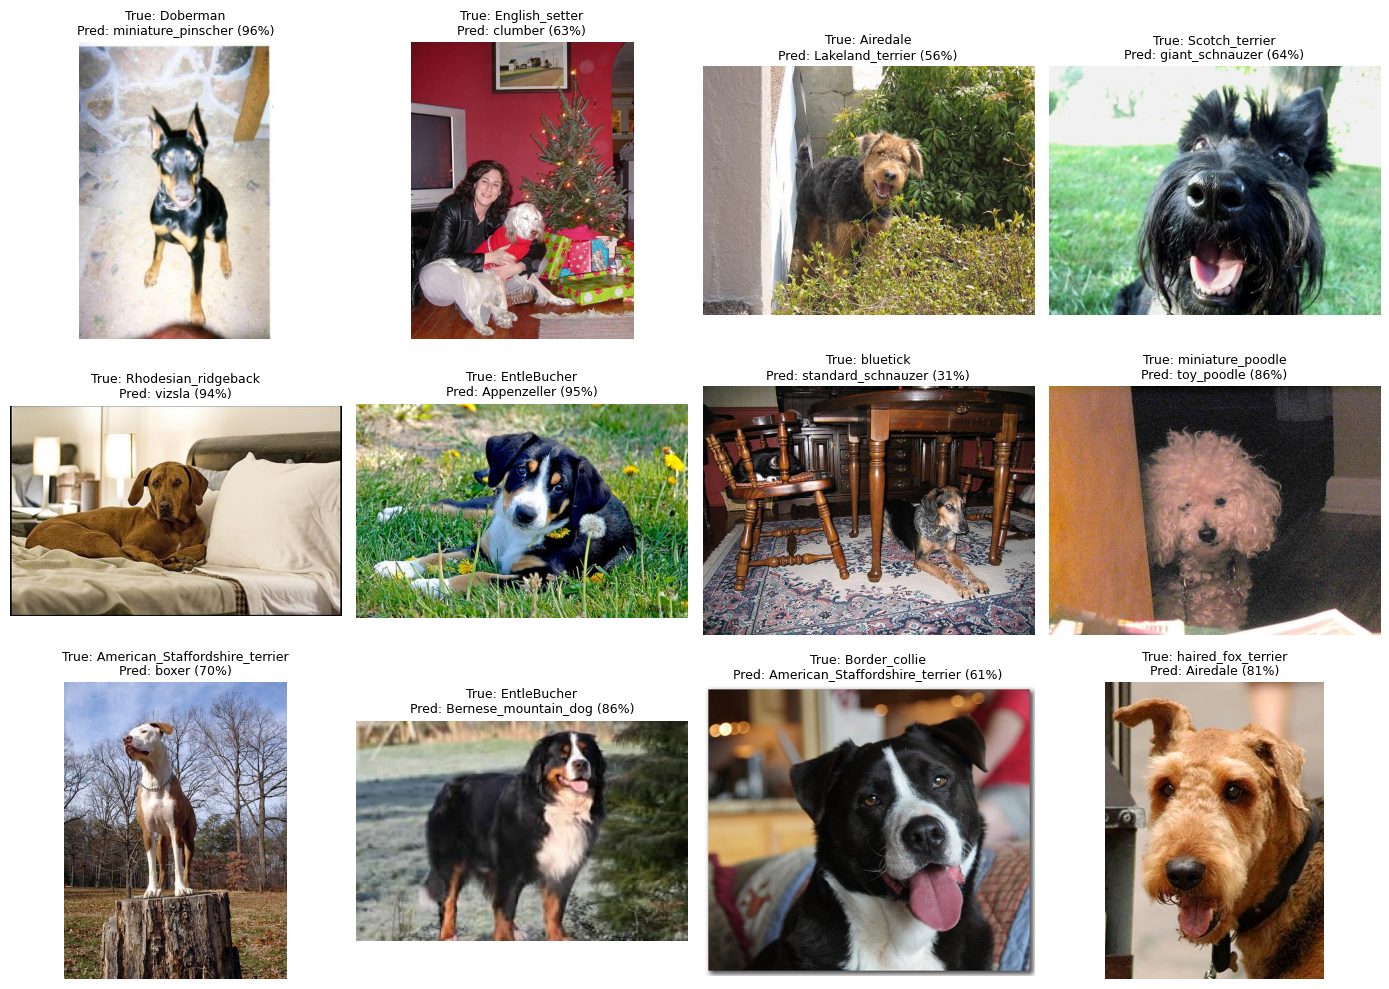

Misclassified: 458 of 3069 (14.9%)


In [19]:
from PIL import Image
wrong = np.where(y_true != y_pred)[0]
rng = np.random.default_rng(SEED)
pick = rng.choice(wrong, size=min(12, len(wrong)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for a, i in zip(axes.ravel(), pick):
    a.imshow(Image.open(test_df[PATH_COL].iloc[i]).convert('RGB')); a.axis('off')
    a.set_title(f"True: {short[y_true[i]]}\nPred: {short[y_pred[i]]} ({probs[i].max():.0%})", fontsize=9)
plt.tight_layout(); plt.show()
print(f'Misclassified: {len(wrong)} of {len(y_true)} ({len(wrong)/len(y_true):.1%})')

### 20.1 Error Findings

- The most frequent confusions are between near-identical breeds: miniature poodle predicted as toy poodle (11 times), Siberian husky as Eskimo dog (9), collie as Shetland sheepdog (8), standard schnauzer as miniature schnauzer (6), silky terrier as Australian terrier (6), collie as Border collie (6), Eskimo dog as malamute (6), EntleBucher as Appenzeller (6).
- Several pairs differ mainly by size (toy/miniature poodle, standard/miniature schnauzer), which is hard to judge from a single photo with no scale reference.
- The same look-alike pairs (schnauzers, Border collie vs collie) caused conflicting-label duplicates during cleaning (Section 9), which suggests some labels in the source data are themselves ambiguous.
- Misclassified images often show multiple dogs, people, unusual poses or tiny dogs in large scenes (Section 10).
- Because the right breed is in the top 5 for 98.3% of images, the model is much more useful as a "top-3 suggestions" tool than as a single final answer.

## Section 21: Model Comparison Summary

All models side by side. Baseline and Stage 1/2 rows are validation results; the last row is the held-out test set.

In [20]:
summary = pd.DataFrame([
    ['Baseline CNN (no aug)',          0.2643, 0.5632, 3.0647, 420696,  16.8],
    ['Baseline CNN (aug)',             0.1780, 0.4580, 3.4773, 420696,  29.2],
    ['EfficientNetB0 - frozen (val)',  r1['accuracy'], r1['top5_acc'], r1['loss'], base.count_params(), round(t1, 1)],
    ['EfficientNetB0 - fine-tuned (val)', r2['accuracy'], r2['top5_acc'], r2['loss'], base.count_params(), round(t2, 1)],
    ['EfficientNetB0 - fine-tuned (TEST)', test_res['accuracy'], test_res['top5_acc'], test_res['loss'], base.count_params(), np.nan],
], columns=['model', 'acc', 'top5', 'loss', 'backbone_params', 'train_min']).round(4)
summary

,model,acc,top5,loss,backbone_params,train_min
0,Baseline CNN (no aug),0.2643,0.5632,3.0647,420696,16.8
1,Baseline CNN (aug),0.1780,0.4580,3.4773,420696,29.2
2,EfficientNetB0 - frozen (val),0.8582,0.9831,0.4394,4049571,10.0
3,EfficientNetB0 - fine-tuned (val),0.8523,0.9834,0.4906,4049571,6.2
4,EfficientNetB0 - fine-tuned (TEST),0.8508,0.9834,0.5146,4049571,NaN


### 21.1 Comparison Findings

- Best model: **EfficientNetB0 with transfer learning** (test accuracy 85.08%, top-5 98.34%, macro F1 0.8454).
- It is about 59 percentage points above the best baseline CNN (26.43% validation accuracy) and uses a pretrained backbone with 4.05M parameters instead of a 420,696-parameter model trained from scratch.
- Stage 1 (frozen backbone) and Stage 2 (fine-tuned) are within noise of each other (85.82% vs 85.23% validation accuracy). Stage 1 had the lower validation loss.
- `backbone_params` is the EfficientNetB0 backbone size; the baseline rows show the whole network.

## Section 22: Saving the Model and Building an Inference Function

The final model and the class-name list are saved so the model can be reused without retraining. The helper `predict_breed` returns the top-3 breeds with probabilities.

Saved model + class names to /content


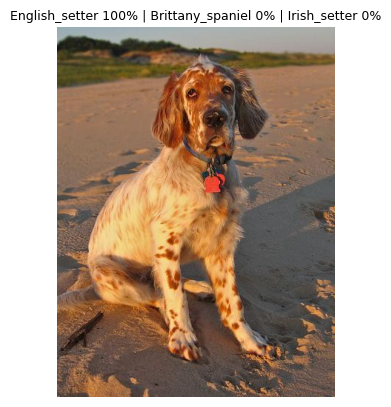

[('English_setter', 0.999775230884552),
 ('Brittany_spaniel', 0.00015010562492534518),
 ('Irish_setter', 5.255407450022176e-05)]

In [21]:
model.save('/content/dog_breed_effnetb0_final.keras')
json.dump(class_names, open('/content/class_names.json', 'w'))
print('Saved model + class names to /content')

def predict_breed(image_path, top_k=3, show=True):
    img = tf.io.decode_image(tf.io.read_file(image_path), channels=3, expand_animations=False)
    img = tf.cast(tf.image.resize(img, (IMG, IMG)), tf.float32)[None]
    p = model.predict(img, verbose=0)[0]
    top = p.argsort()[::-1][:top_k]
    if show:
        plt.imshow(Image.open(image_path).convert('RGB')); plt.axis('off')
        plt.title(' | '.join(f"{short[i]} {p[i]:.0%}" for i in top), fontsize=9); plt.show()
    return [(short[i], float(p[i])) for i in top]

predict_breed(test_df[PATH_COL].iloc[0])

### 22.1 Inference Check

- The model is saved as `dog_breed_effnetb0_final.keras` with `class_names.json` (breed order matches the `label` column).
- Example prediction on a test image: English setter with 99.98% probability, followed by Brittany spaniel and Irish setter with negligible probability.
- Files in `/content` are deleted when the Colab session ends, so they are downloaded to a local computer or Google Drive.

## Section 23: Conclusion, Limitations and Future Work

### 23.1 Conclusion

- A 120-breed dog classifier was built end to end: data audit, cleaning (126 duplicate or conflicting images removed), a stratified 70/15/15 split with no leakage, a `tf.data` pipeline, two baseline CNNs and a two-stage EfficientNetB0 transfer-learning model.
- The baseline CNNs underfit (best validation accuracy 26.43%). Transfer learning reached **85.08% test accuracy, 98.34% top-5 accuracy and 0.8454 macro F1**.
- Most remaining errors are between look-alike breeds, and the correct breed is in the top 5 predictions for 98.3% of test images.

### 23.2 Key Lessons

- Check data quality first: cross-breed duplicates would have given the model wrong labels and leaked images between splits.
- Read the training curves before changing the model: the baselines showed underfitting, Stage 2 showed mild overfitting.
- Pretrained features beat a small CNN trained from scratch on limited, fine-grained data.
- More tuning is not always better: fine-tuning did not improve on the frozen backbone.

### 23.3 Challenges Faced

- 37 cross-breed duplicate pairs with conflicting labels, and one PNG saved as `.jpg`.
- Colab memory limits: images are streamed with `tf.data` instead of being loaded into one array.
- Early augmentation settings darkened images and created mirrored corner artifacts, so they were revised (Section 12).
- Baseline CNNs underfit, and fine-tuning overfit slightly.

### 23.4 Limitations

- Look-alike breeds (poodle sizes, schnauzer sizes, husky/Eskimo dog, collie/Sheltie) remain hard, and some source labels appear ambiguous.
- Only one pretrained backbone was tested, and its augmentation (zoom ±10% with default fill) is simpler than the revised settings in Section 12.
- The folder names are ImageNet class IDs, so the dataset appears to be drawn from ImageNet. Some images may have been seen by the backbone during its original training, so test accuracy may be somewhat optimistic for completely new photos.
- Multiple dogs in one image, mixed breeds and breeds outside the 120 are out of scope.

### 23.5 Future Work

- Compare other backbones (MobileNetV2, EfficientNetB3/V2, ConvNeXt) and larger input sizes.
- Try gentler fine-tuning (smaller learning rate, label smoothing, mixup/cutmix) and test-time augmentation.
- Add Grad-CAM to check that the model looks at the dog and not the background.
- Deploy as a Streamlit or Gradio app using the saved model.

### 23.6 Recommendation

The model is suitable for a "suggest the top 3 likely breeds" feature (shelters, pet-adoption or photo apps), where the right breed is almost always shown. It should not be used as the only authority for look-alike breeds, where a human check is needed.